In [8]:
# Import necessary Qiskit libraries and primitives
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## Part 1: Predictions (Think Before You Run)

1. **Will 0 or 1 occur more frequently?**
   * For our primary biased coin circuit, outcome **'1'** will occur more frequently.

2. **Approximately what percentage of the measurements?**
   * Roughly **75%** for outcome '1' and **25%** for outcome '0' (derived from the squared probability amplitudes of the $R_y$ rotation).

3. **What happens if you change the gates?**
   * Changing the rotation angle $\theta$ alters the state vector's position on the Bloch sphere, directly shifting the statistical distribution and changing the bias ratio between 0 and 1.

Circuit 1 (Favors '1'):


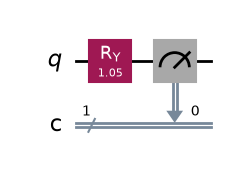

In [9]:
# Circuit 1: Biased to favor outcome '1' (~75% probability for 1, 25% for 0)
# Constraints: 1 qubit, 1 measurement, 1 gate (<= 4 gates limit)

qc_biased_1 = QuantumCircuit(1, 1)
qc_biased_1.ry(3.14159 / 3, 0)  # Apply rotation gate around Y-axis
qc_biased_1.measure(0, 0)

# Display the circuit diagram
print("Circuit 1 (Favors '1'):")
display(qc_biased_1.draw('mpl'))

In [10]:
# Execute Circuit 1 for 100 shots
sampler = StatevectorSampler()
job_1 = sampler.run([qc_biased_1], shots=100)
result_1 = job_1.result()

counts_1 = result_1[0].data.c.get_counts()
print("Measurement Results for Circuit 1 (100 shots):", counts_1)

Measurement Results for Circuit 1 (100 shots): {'0': 71, '1': 29}


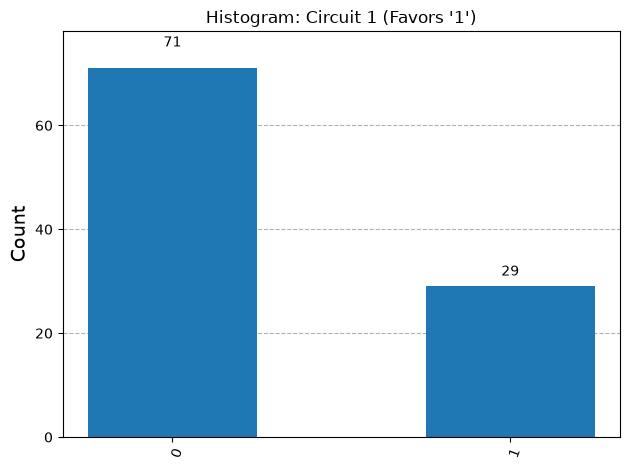

In [11]:
# Display Histogram for Circuit 1
plot_histogram(counts_1, title="Histogram: Circuit 1 (Favors '1')")

---
## Bonus Challenge: Comparing Two Different Circuits
To demonstrate different degrees and directions of bias, we design two distinct circuits:
* **Circuit A (Favors `0`):** Uses a smaller rotation angle ($\pi/6$), yielding higher probability for `0`.
* **Circuit B (Favors `1`):** Uses a larger rotation angle ($2\pi/3$), yielding higher probability for `1`.

In [12]:
# Bonus Circuit A: Favors '0'
qc_favors_0 = QuantumCircuit(1, 1)
qc_favors_0.ry(3.14159 / 6, 0)  # Smaller rotation angle
qc_favors_0.measure(0, 0)

# Bonus Circuit B: Favors '1'
qc_favors_1 = QuantumCircuit(1, 1)
qc_favors_1.ry(3.14159 * 2 / 3, 0)  # Larger rotation angle
qc_favors_1.measure(0, 0)

# Execute both for 100 shots
job_a = sampler.run([qc_favors_0], shots=100)
job_b = sampler.run([qc_favors_1], shots=100)

counts_a = job_a.result()[0].data.c.get_counts()
counts_b = job_b.result()[0].data.c.get_counts()

print("Results - Favors 0 (100 shots):", counts_a)
print("Results - Favors 1 (100 shots):", counts_b)

Results - Favors 0 (100 shots): {'0': 90, '1': 10}
Results - Favors 1 (100 shots): {'1': 71, '0': 29}


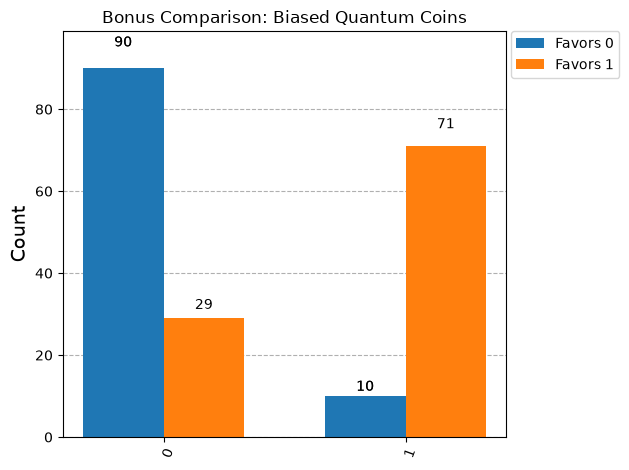

In [13]:
# Compare histograms side-by-side (or individually)
plot_histogram([counts_a, counts_b], legend=['Favors 0', 'Favors 1'], title="Bonus Comparison: Biased Quantum Coins")

### Challenge Question & Explanation

**Question:** How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

**Answer:** 
Quantum gates act mathematically as unitary matrices that rotate or transform the state vector of a qubit on the Bloch sphere. When we apply a single-qubit rotation gate like $R_y(\theta)$, it modifies the complex amplitudes ($\alpha$ and $\beta$) of the computational basis states $\vert 0 \rangle$ and $\vert 1 \rangle$. According to the Born rule, the probability of measuring a specific outcome is equal to the squared magnitude of its probability amplitude ($\vert \alpha \vert^2$ and $\vert \beta \vert^2$). By adjusting the rotation angle $\theta$, we precisely control these amplitudes, directly shifting the statistical distribution and making the quantum coin biased toward either $\vert 0 \rangle$ or $\vert 1 \rangle$.